# 00 — Stitching from scratch: learning a Wasserstein gradient flow from snapshots

Clean-room reproduction of **Heinonen et al., *Wasserstein Residuals: Learning Gradient Flows from Population Dynamics*** (arXiv:2607.04738, in this folder as `2607.04738v1.pdf`).
Written from the paper and our notes (`OT_Wasserstein_GF_math_notes.pdf`, `00_reference_repo_structure.md`), with no code from the reference repo.

**Goal.** We only see *snapshots* $q_t$ of a population at a few times, with no particle identities. We want an energy
$$\mathcal F_\theta[\rho] = c_V\!\int V_\theta\,d\rho \;+\; c_H\!\int \rho\log\rho \;+\; \tfrac{c_W}{2}\!\iint W_\theta(x-y)\,d\rho(x)\,d\rho(y)$$
whose Wasserstein gradient flow $\partial_t\rho = \nabla\!\cdot\!\big(\rho\,\nabla\tfrac{\delta\mathcal F_\theta}{\delta\rho}\big)$ reproduces the snapshots.

**Test problem.** The 1-D double-well $V^\star(x)=\tfrac12(|x|-7)^2$ with temperature $\beta=1$, so we know the right answer.

### How this notebook is organised
Every code block sits under one of five banners, and each is preceded by a markdown cell giving the formula it implements.

| Banner | What it is | Paper |
|---|---|---|
| `# ═══ [DATA] ═══` | simulate the true system, build the snapshots | Eq. 15, App. E |
| `# ═══ [NN] ═══` | the learnable model: particles + KDE + networks $V_\theta$, $W_\theta$ → force $g$ | Eqs. 7, 8, 14, 36–37 |
| `# ═══ [LOSS] ═══` | data term (NLL) + physics term (velocity residual) | Eqs. 6, 13, 27–28 |
| `# ═══ [OPTIMISER / GD] ═══` | Adam + cosine schedule, full batch | §5, App. E |
| `# ═══ [EVAL] ═══` | coefficients, potential $R^2$, held-out $W_1$ | §5, App. F |

Cells marked **✔ check** are sanity tests with a known answer; they should print `True`/`OK`.

### Notation
| Symbol | Meaning | Code |
|---|---|---|
| $D$ | dimension (here $1$) | `D` |
| $t_0<\dots<t_{K-1}$ | model time grid, $\Delta t_j = t_{j+1}-t_j$ | `model.t_grid` |
| $x_{j,k}\in\mathbb R^D$ | position of model particle $k$ at grid time $t_j$ | `model.X[j, k]`, shape `(K, N, D)` |
| $w_k$ | particle weight, $\sum_k w_k = 1$ (frozen at $1/N$) | `model.logw` |
| $h\in\mathbb R^D_{>0}$ | KDE bandwidth (diagonal) | `model.h` |
| $\rho_t$ | model density at time $t$ (a KDE) | `log_kde` |
| $g = \nabla\frac{\delta\mathcal F}{\delta\rho}$ | energy gradient per unit mass; the flow velocity is $v=-g$ | `model.force` |
| $q_s$, $\{y_{s,i}\}$ | observed snapshot at time $s$ | `train[s]` |

In [1]:
import inspect, math, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment

ROOT = Path.cwd().resolve()
if not (ROOT / "wgf").exists():          # notebook lives in notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from wgf import potentials as P
from wgf.sim import em_step, simulate

torch.set_default_dtype(torch.float64)
SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
print("torch", torch.__version__)

torch 2.8.0


---
# 1 · `[DATA]` — the true system and its snapshots

### 1.1 The ground-truth flow
The true energy is $\mathcal F^\star[\rho] = \int V^\star d\rho + \beta\int\rho\log\rho$, whose Wasserstein gradient flow is the Fokker–Planck equation
$$\partial_t\rho = \nabla\!\cdot\!\big(\rho\,\nabla V^\star\big) + \beta\,\Delta\rho .$$
At the particle level this is the SDE $dX_t = -\nabla V^\star(X_t)\,dt + \sqrt{2\beta}\,dB_t$ (paper Eq. 15, here without interaction).

### 1.2 The forward step (Euler–Maruyama)
Superscript $n$ = time step, subscripts $i,j$ = particles:
$$X^{n+1}_i = X^n_i - \Delta t\Big[\nabla V(X^n_i) + \tfrac1N\textstyle\sum_{j=1}^N \nabla W(X^n_i - X^n_j)\Big] + \sqrt{2\beta\,\Delta t}\;\varepsilon^n_i,\qquad \varepsilon^n_i\sim\mathcal N(0,I).$$
All forces are computed from the cloud at time $n$ before anyone moves (vectorised), so the result does not depend on particle order.
The noise is $\sigma=\sqrt{2\beta}$ (the reference code uses $\sqrt2\,c_H$; see notes §11.2). Implementation: [`wgf/sim.py`](../wgf/sim.py), tested in `tests/test_sim.py`.

In [2]:
# ═══ [DATA] ═══  the step we use (printed from wgf/sim.py so you can read it here)
print(inspect.getsource(em_step))

def em_step(
    X: torch.Tensor,
    dt: float,
    beta: float,
    grad_V: Optional[GradFn] = None,
    grad_W: Optional[GradFn] = None,
    weights: Optional[torch.Tensor] = None,
    generator: Optional[torch.Generator] = None,
) -> torch.Tensor:
    """One explicit Euler–Maruyama step. Uses only the cloud at time n."""
    g = drift(X, grad_V, grad_W, weights)
    X_new = X - dt * g
    if beta > 0:
        noise = torch.randn(X.shape, generator=generator, dtype=X.dtype, device=X.device)
        X_new = X_new + (2.0 * beta * dt) ** 0.5 * noise
    return X_new



### 1.3 Observation protocol
* Simulate $N_\text{sim}=1000$ particles from $X_0\sim\mathcal N(0,1)$ with $\Delta t = 0.01$.
* Split the particles 50/50 into **train** and **test**.
* **Train snapshots** at $s\in\{0,1,2,3,4\}$. We keep only the clouds, never the particle identities, so the model sees *unpaired* marginals $q_s$.
* **Held-out times** $\{0.5,1.5,2.5,3.5\}$ (test particles only) are used in `[EVAL]` to check interpolation between snapshots.

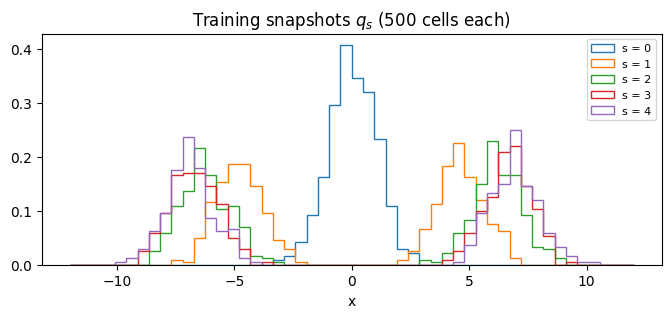

In [3]:
# ═══ [DATA] ═══  simulate the ground truth and build train / test snapshots
BETA_TRUE = 1.0
grad_V_true = P.grad_double_well_1d
V_true = P.double_well_1d

N_SIM, D = 1000, 1
T_TRAIN = [0.0, 1.0, 2.0, 3.0, 4.0]
T_HELD = [0.5, 1.5, 2.5, 3.5]
T_ALL = sorted(T_TRAIN + T_HELD)

gen = torch.Generator().manual_seed(SEED)
X0 = torch.randn(N_SIM, D, generator=gen)
traj = simulate(X0, T_ALL, dt=0.01, beta=BETA_TRUE, grad_V=grad_V_true, generator=gen)   # (len(T_ALL), N_SIM, D)

perm = torch.randperm(N_SIM, generator=gen)
idx_tr, idx_te = perm[: N_SIM // 2], perm[N_SIM // 2 :]
snap = {t: traj[i] for i, t in enumerate(T_ALL)}
train = {t: snap[t][idx_tr][torch.randperm(len(idx_tr), generator=gen)] for t in T_TRAIN}  # shuffled: no identities
test = {t: snap[t][idx_te] for t in T_ALL}

fig, ax = plt.subplots(figsize=(8, 3))
for t in T_TRAIN:
    ax.hist(train[t][:, 0].numpy(), bins=50, range=(-12, 12), density=True, histtype="step", label=f"s = {t:g}")
ax.set(title="Training snapshots $q_s$ (500 cells each)", xlabel="x"); ax.legend(fontsize=8)
plt.show()

---
# 2 · `[NN]` — the learnable model

### 2.1 What is learned
| Parameter | Shape | Constraint | Init | Role |
|---|---|---|---|---|
| positions $x_{j,k}$ | $(K,N,D)$ | none | OT-matched straight lines + jitter (§2.6) | the curve $\rho_t$ |
| $V_\theta$ | MLP $D\to64\to64\to1$ | — | last layer zeroed ⇒ $V_\theta\equiv0$ | potential |
| $W_\theta$ (optional) | MLP on $\lVert r\rVert^2$: $1\to64\to64\to1$ | radial ⇒ even | zeroed | interaction |
| $h$ | $(D,)$ | softplus | Silverman on the $s=0$ snapshot | bandwidth |
| $c_H$ | scalar | softplus | $0.5$ (truth $\beta=1$) | entropy weight |
| $c_V$ | — | fixed $=1$ | — | **our choice**: $c_V V_\theta$ has a scale redundancy, so we let $V_\theta$ carry the scale |
| $w_k$ | $(N,)$ | softmax | uniform | frozen, as in the paper presets |
| $t_j$ | $(K,)$ | — | `linspace` | frozen |

Most trainable numbers are particle positions ($K\cdot N\cdot D$), not network weights.

### 2.2 The curve: a KDE over moving particles (paper Eq. 8)
$$\rho_t(x) = \sum_{k=1}^N w_k\,\varphi_h(x - x_{t,k}),\qquad \varphi_h(z)=\prod_{d=1}^D \frac{1}{\sqrt{2\pi}\,h_d}\exp\!\Big(-\frac{z_d^2}{2h_d^2}\Big).$$
For numerical stability we evaluate it in log space with a log-sum-exp:
$$\log\rho_t(y) = \operatorname*{logsumexp}_k\Big[\log w_k - \tfrac12\sum_d \tfrac{(y_d-x_{t,k,d})^2}{h_d^2}\Big] - \sum_d\log h_d - \tfrac D2\log 2\pi .$$
Off-grid times use linear interpolation of the centres: $x_{s,k} = (1-a)\,x_{j,k} + a\,x_{j+1,k}$ with $a=\frac{s-t_j}{t_{j+1}-t_j}$.
By paper Claim 1 the Nadaraya–Watson field $v_t(x)=\frac{\sum_k w_k\varphi_h(x-x_{t,k})\,\dot x_{t,k}}{\sum_l w_l\varphi_h(x-x_{t,l})}$ (Eq. 9) makes $(\rho,v)$ satisfy the continuity equation exactly, so $\rho$ is always a valid curve of probability densities.

In [4]:
# ═══ [NN] ═══  KDE log-density (Eq. 8)
def log_kde(y, centres, h, logw):
    # y: (M, D) query points; centres: (N, D); h: (D,); logw: (N,) log-weights summing to 1
    z = (y[:, None, :] - centres[None, :, :]) / h          # (M, N, D)
    logk = -0.5 * (z ** 2).sum(-1)                         # (M, N)
    norm = torch.log(h).sum() + 0.5 * y.shape[1] * math.log(2 * math.pi)
    return torch.logsumexp(logw[None, :] + logk, dim=1) - norm   # (M,)

### 2.3 The entropy force: the KDE score (paper Eqs. 36–37)
For $\mathcal H[\rho]=\int\rho\log\rho$ we have $\frac{\delta\mathcal H}{\delta\rho} = \log\rho + 1$, so its force is the **score** $\nabla\log\rho$. For a Gaussian KDE, $\nabla\varphi_h(z) = -\frac{z}{h^2}\varphi_h(z)$, which gives the closed form
$$\nabla\log\rho_t(x) = \sum_k r_k(x)\,\frac{x_{t,k}-x}{h^2},\qquad r_k(x) = \frac{w_k\varphi_h(x-x_{t,k})}{\sum_l w_l\varphi_h(x-x_{t,l})}\quad(\text{a softmax}).$$
It points from $x$ towards a softmax-weighted average of the particles. We need it **at the centres** $x = x_{t,j}$:

* **full** score: keep $k=j$. This is the exact score of the model density (what the reference code does).
* **leave-one-out (LOO)**, paper Eq. 37: drop $k=j$ from numerator *and* denominator. The self-term adds nothing to the numerator ($x_j-x_j=0$) but adds the peak value $w_j\varphi_h(0)$ to the denominator, which shrinks the score when neighbours are far away.

We default to **LOO**, as the paper's text prescribes; switch `SCORE` to `"full"` for the ablation.

In [5]:
# ═══ [NN] ═══  analytic score at the centres, for all grid times at once (Eqs. 36-37)
def kde_score_at_centres(X, h, logw, loo=True):
    # X: (K, N, D) centres at every grid time -> (K, N, D) score at each centre
    diff = X[:, :, None, :] - X[:, None, :, :]             # (K, N_j, N_k, D): x_j - x_k
    logits = logw + (-0.5 * ((diff / h) ** 2).sum(-1))     # (K, N, N)  log(w_k phi_h(x_j - x_k)) + const
    if loo:
        eye = torch.eye(X.shape[1], dtype=torch.bool)
        logits = logits.masked_fill(eye, float("-inf"))
    r = torch.softmax(logits, dim=-1)                      # r_jk, rows sum to 1
    return -(r[..., None] * diff).sum(2) / h ** 2          # sum_k r_jk (x_k - x_j) / h^2

**✔ check.** (a) The full analytic score equals the autograd gradient of `log_kde`. (b) The worked example from our notes §9.2: particles at $0,\,0.5,\,1.4$, $h=0.4$, evaluated at $0.5$, gives full $\approx-0.64$ and LOO $\approx-1.83$.

In [6]:
# ═══ [NN] ═══ ✔ check
Xc = torch.randn(3, 40, 2)                                 # 3 times, 40 particles, 2-D
hc, lw = torch.tensor([0.3, 0.5]), torch.full((40,), -math.log(40))
s_full = kde_score_at_centres(Xc, hc, lw, loo=False)
y = Xc[1].clone().requires_grad_(True)
s_auto = torch.autograd.grad(log_kde(y, Xc[1], hc, lw).sum(), y)[0]
print("(a) analytic full score == autograd:", torch.allclose(s_full[1], s_auto, atol=1e-10))

Xn = torch.tensor([[[0.0], [0.5], [1.4]]]); hn = torch.tensor([0.4]); lwn = torch.full((3,), -math.log(3))
print("(b) full  score at 0.5: %.2f" % kde_score_at_centres(Xn, hn, lwn, loo=False)[0, 1, 0].item())
print("    LOO   score at 0.5: %.2f" % kde_score_at_centres(Xn, hn, lwn, loo=True)[0, 1, 0].item())

(a) analytic full score == autograd: True
(b) full  score at 0.5: -0.64
    LOO   score at 0.5: -1.83


### 2.4 The networks $V_\theta$ and $W_\theta$
**MLP block.** `Linear → SiLU`, plus a residual skip $y\leftarrow y+\mathrm{SiLU}(Ly)$ when in- and out-widths match, then a final `Linear` whose weights are **zeroed**, so training starts from $V_\theta\equiv0$ (no force from the potential). SiLU is smooth, which matters because we differentiate $V_\theta$ in $x$ and then again in $\theta$.

**Radial interaction.** $W_\theta(r) = \mathrm{MLP}(\lVert r\rVert^2)$ is even by construction, and
$\nabla W_\theta(r) = 2\,\mathrm{MLP}'(\lVert r\rVert^2)\,r$, so $\nabla W_\theta(0)=0$ and the self-term $l=k$ is harmless.

**Gradients inside a loss.** $\nabla_x V_\theta$ appears inside the loss, which we then differentiate in $\theta$. So we call `torch.autograd.grad(..., create_graph=True)`, a gradient of a gradient.

In [7]:
# ═══ [NN] ═══  MLP with SiLU, residual skips and a zero-initialised head
class MLP(nn.Module):
    def __init__(self, d_in, hidden=(64, 64), d_out=1):
        super().__init__()
        widths = (d_in,) + tuple(hidden)
        self.layers = nn.ModuleList(nn.Linear(a, b) for a, b in zip(widths[:-1], widths[1:]))
        self.head = nn.Linear(widths[-1], d_out)
        nn.init.zeros_(self.head.weight); nn.init.zeros_(self.head.bias)

    def forward(self, x):
        for L in self.layers:
            y = F.silu(L(x))
            x = x + y if y.shape == x.shape else y        # residual skip when widths match
        return self.head(x).squeeze(-1)


def grad_x(f, x):
    # grad_x f(x) for a row-wise scalar f, kept differentiable in the parameters of f
    with torch.enable_grad():                              # also works inside torch.no_grad()
        if not x.requires_grad:
            x = x.detach().requires_grad_(True)
        return torch.autograd.grad(f(x).sum(), x, create_graph=True)[0]

### 2.5 The force $g = \nabla\frac{\delta\mathcal F_\theta}{\delta\rho}$ at each particle (paper Eqs. 7, 14)
$$g_{j,k} = c_V\,\nabla V_\theta(x_{j,k}) \;+\; c_H\,\nabla\log\rho_{t_j}(x_{j,k}) \;+\; c_W\sum_{l} w_l\,\nabla W_\theta(x_{j,k}-x_{j,l}).$$
Each term uses only the particles at the **same** grid time $t_j$. The interaction sum is approximated on the centres (Eq. 14), and the score uses §2.3. The flow velocity is $v=-g$.

### 2.6 Initialisation of the particles
1. Match the first and last training snapshots by exact OT on the squared cost (Hungarian, `linear_sum_assignment`).
2. Pick $N$ matched pairs at random and join each pair by a straight line across the $K$ grid times (the $W_2$ geodesic between two Diracs).
3. Add a small Gaussian jitter per particle (1 % of the data range), the same at every time.

The interior snapshots play no part here; they enter only through the NLL.
**Bandwidth init:** Silverman's rule $h_d = 1.06\,\hat\sigma_d\,M^{-1/5}$ on the $s=0$ snapshot.

In [8]:
# ═══ [NN] ═══  the Stitching model: parameters, curve, force
def inv_softplus(y):
    return math.log(math.expm1(y))


class Stitching(nn.Module):
    def __init__(self, train, K=50, N=100, c_H0=0.5, interaction=False, score="loo", seed=0):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        times = sorted(train)
        D = train[times[0]].shape[1]
        self.register_buffer("t_grid", torch.linspace(times[0], times[-1], K))      # frozen
        self.register_buffer("logw", torch.full((N,), -math.log(N)))                # frozen uniform weights
        self.loo = score == "loo"

        # §2.6 OT-matched straight lines + jitter
        A, B = train[times[0]], train[times[-1]]
        rows, cols = linear_sum_assignment(torch.cdist(A, B).pow(2).numpy())
        pick = torch.randint(len(rows), (N,), generator=g)
        a, b = A[rows[pick]], B[cols[pick]]                                          # (N, D) each
        s = ((self.t_grid - self.t_grid[0]) / (self.t_grid[-1] - self.t_grid[0]))[:, None, None]
        span = torch.cat([A, B]).amax(0) - torch.cat([A, B]).amin(0)
        jitter = 0.01 * span * torch.randn(N, D, generator=g)
        self.X = nn.Parameter((1 - s) * a + s * b + jitter)                         # (K, N, D)

        # positive scalars through softplus
        h0 = 1.06 * A.std(0) * len(A) ** (-1 / 5)                                    # Silverman
        self.raw_h = nn.Parameter(torch.log(torch.expm1(h0)))
        self.raw_cH = nn.Parameter(torch.tensor(inv_softplus(c_H0)))
        self.c_V = 1.0                                                               # fixed (scale redundancy)

        self.V = MLP(D)
        self.W = MLP(1) if interaction else None
        self.raw_cW = nn.Parameter(torch.tensor(0.0)) if interaction else None

    h = property(lambda self: F.softplus(self.raw_h))
    c_H = property(lambda self: F.softplus(self.raw_cH))
    c_W = property(lambda self: F.softplus(self.raw_cW) if self.W is not None else 0.0)

    def centres_at(self, s):
        # linear interpolation of the centres at an arbitrary time s -> (N, D)
        t = self.t_grid
        j = int(torch.clamp(torch.searchsorted(t, torch.tensor(float(s)), right=True) - 1, 0, len(t) - 2))
        a = (s - t[j]) / (t[j + 1] - t[j])
        return (1 - a) * self.X[j] + a * self.X[j + 1]

    def grad_V(self, x):
        return grad_x(self.V, x)

    def force(self, X=None):
        # g = c_V grad V + c_H grad log rho + c_W sum_l w_l grad W(x_k - x_l), at every (j, k) -> (K, N, D)
        X = self.X if X is None else X
        K, N, D = X.shape
        g = self.c_V * self.grad_V(X.reshape(-1, D)).reshape(K, N, D)
        g = g + self.c_H * kde_score_at_centres(X, self.h, self.logw, loo=self.loo)
        if self.W is not None:
            diff = X[:, :, None, :] - X[:, None, :, :]                               # (K, N, N, D)
            r2 = (diff ** 2).sum(-1, keepdim=True)
            dW = torch.autograd.grad(self.W(r2).sum(), r2, create_graph=True)[0]     # MLP'(|r|^2)
            g = g + self.c_W * torch.einsum("jkld,l->jkd", 2 * dW * diff, self.logw.exp())
        return g

In [9]:
# ═══ [NN] ═══  build the model and count what is trainable
K, N = 50, 100
SCORE = "loo"                      # "loo" (paper Eq. 37) or "full" (reference code)
torch.manual_seed(SEED)            # the MLP init uses the global RNG
model = Stitching(train, K=K, N=N, c_H0=0.5, score=SCORE, seed=SEED)

n_pos = model.X.numel()
n_net = sum(p.numel() for n_, p in model.named_parameters() if n_.startswith("V."))
print(f"particle positions: {n_pos:,}   V_theta weights: {n_net:,}   scalars: h, c_H")
print(f"init: h = {model.h.item():.3f}, c_H = {model.c_H.item():.3f}, grid dt = {(model.t_grid[1]-model.t_grid[0]).item():.4f}")

particle positions: 5,000   V_theta weights: 4,353   scalars: h, c_H
init: h = 0.309, c_H = 0.500, grid dt = 0.0816


---
# 3 · `[LOSS]` — data term + physics term

The global objective (paper Eq. 6) is
$$\mathcal L(\theta) = \underbrace{\sum_{s\in\mathcal T_\text{obs}}\mathcal D(\rho^\theta_s, q_s)}_{\text{data: fit the snapshots}} \;+\; \lambda\,\underbrace{\mathcal R_\text{vel}[\mathcal F_\theta,\rho^\theta]}_{\text{physics: be a gradient flow}},\qquad \lambda = 1 .$$

### 3.1 Data term: negative log-likelihood (paper Eqs. 27–28)
With $\mathcal D = $ KL, up to a constant that does not depend on $\theta$:
$$\mathcal D_\text{KL}(\rho_s,q_s) \approx -\frac1{M_s}\sum_{i=1}^{M_s}\log\rho_s(y_{s,i}).$$
**Our choice:** a mean *per snapshot*, then a sum over snapshots, so each snapshot has equal weight as in the paper's $\sum_s$. The reference code pools all points, which weights snapshots by their size (notes §11.6).

In [10]:
# ═══ [LOSS] ═══  data term: per-snapshot NLL, summed over snapshots
def nll_loss(model, train):
    return sum(-log_kde(y, model.centres_at(s), model.h, model.logw).mean() for s, y in train.items())

### 3.2 Physics term: the velocity residual, from the integral to Eq. 13
The residual is zero exactly when $\rho$ is a gradient flow of $\mathcal F$:
$$\mathcal R_\text{vel} = \int_0^T\!\!\int \Big\lVert v_t(x) + \nabla\tfrac{\delta\mathcal F}{\delta\rho_t}(x)\Big\rVert^2\rho_t(x)\,dx\,dt .$$
1. **Particles instead of the KDE** (Eq. 11): integrate against $\sum_k w_k\delta_{x_{t,k}}$, and use $v_t(x_{t,k}) = \dot x_{t,k}$ (Claim 2):
$\;\mathcal R_\text{vel}\approx\int_0^T\sum_k w_k\lVert\dot x_{t,k} + g_t(x_{t,k})\rVert^2dt.$
2. **Time grid:** $\dot x \approx \Delta x_{j,k}/\Delta t_j$ with $\Delta x_{j,k}=x_{j+1,k}-x_{j,k}$, plus a Riemann sum. The identity $\Delta t\,\big\lVert\tfrac{a}{\Delta t}+b\big\rVert^2 = \tfrac1{\Delta t}\lVert a+\Delta t\,b\rVert^2$ then gives
$$\boxed{\;\widehat{\mathcal R} = \sum_{j=0}^{K-2}\frac{1}{\Delta t_j}\sum_{k=1}^N w_k\,\big\lVert\Delta x_{j,k} + \Delta t_j\,\bar g_{j,k}\big\rVert^2\;}$$
   * **Euler** (paper Eq. 13): $\bar g_{j,k}=g_{j,k}$. Then $\widehat{\mathcal R}=0$ exactly on forward-Euler paths $x_{j+1}=x_j-\Delta t_j\,g_j$.
   * **Trapezoid** (App. C, the experiments' default): $\bar g_{j,k}=\tfrac12(g_{j,k}+g_{j+1,k})$, second-order accurate.

This is **not** a forward simulation. All $K$ slices of $X$ exist at once as parameters, and $\widehat{\mathcal R}$ checks whether the whole path is consistent with the flow. That is why using $g_{j+1}$ is fine here.

In [11]:
# ═══ [LOSS] ═══  physics term: discretised velocity residual (Eq. 13 / App. C)
def residual(model, scheme="trapezoid"):
    g = model.force()                                   # (K, N, D)
    dX = model.X[1:] - model.X[:-1]                     # (K-1, N, D)
    dt = (model.t_grid[1:] - model.t_grid[:-1])[:, None, None]
    g_bar = g[:-1] if scheme == "euler" else 0.5 * (g[:-1] + g[1:])
    per_particle = ((dX + dt * g_bar) ** 2).sum(-1)     # (K-1, N)
    return ((per_particle * model.logw.exp()).sum(-1) / dt[:, 0, 0]).sum()

**✔ check.** Build a path by forward Euler with the model's *own* force, $x_{j+1}=x_j-\Delta t_j\,g_j(x_j)$. The Euler residual must then be $0$ up to round-off, and a perturbed path must give a positive residual. At init $V_\theta\equiv0$, so the force is pure entropy: the particles spread out.

We build this path with the **full** score. With the LOO score, explicit Euler at this grid step is *unstable*: an isolated particle feels $\lVert\nabla\log\rho\rVert\sim\text{distance}/h^2$, overshoots, and the path blows up (try `model.loo = True` below). This is one reason the model never steps forward in time. The residual only *scores* a path whose slices are all free parameters.

In [12]:
# ═══ [LOSS] ═══ ✔ check
X_saved = model.X.detach().clone()
model.loo = False                                                          # full score: stable Euler path
with torch.no_grad():
    path = [X_saved[0]]
    for j in range(K - 1):
        gj = model.force(torch.stack([path[-1]]))[0].detach()            # force at slice j only
        path.append(path[-1] - (model.t_grid[j + 1] - model.t_grid[j]) * gj)
    model.X.copy_(torch.stack(path))
R_euler = residual(model, "euler").item()
R_trap = residual(model, "trapezoid").item()
with torch.no_grad():
    model.X.add_(0.01 * torch.randn_like(model.X))
R_pert = residual(model, "euler").item()
with torch.no_grad():
    model.X.copy_(X_saved)                                                 # restore the init
model.loo = SCORE == "loo"
print(f"Euler residual on an Euler path : {R_euler:.2e}   (should be ~0)")
print(f"trapezoid residual, same path   : {R_trap:.2e}   (small but not 0: other scheme)")
print(f"Euler residual, perturbed path  : {R_pert:.2e}   (> 0)")
print("OK" if R_euler < 1e-20 and R_pert > 1e-3 else "FAILED")

Euler residual on an Euler path : 3.65e-30   (should be ~0)
trapezoid residual, same path   : 9.83e-05   (small but not 0: other scheme)
Euler residual, perturbed path  : 1.26e-01   (> 0)
OK


### 3.3 Total loss
$$\mathcal L = \mathrm{NLL} + \lambda\,\widehat{\mathcal R},\qquad\lambda=1,\ \text{trapezoid scheme}.$$

In [13]:
# ═══ [LOSS] ═══  total objective (Eq. 6)
LAMBDA, SCHEME = 1.0, "trapezoid"

def total_loss(model, train):
    nll = nll_loss(model, train)
    R = residual(model, SCHEME)
    return nll + LAMBDA * R, nll, R

---
# 4 · `[OPTIMISER / GD]` — Adam on everything at once

**Full batch:** every step uses all snapshots and all $K$ slices. One step per "epoch".

**Adam** (per parameter, $\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-8}$):
$$m\leftarrow\beta_1 m+(1-\beta_1)\nabla_\theta\mathcal L,\quad v\leftarrow\beta_2 v+(1-\beta_2)(\nabla_\theta\mathcal L)^2,\quad \theta\leftarrow\theta-\eta_n\,\frac{\hat m}{\sqrt{\hat v}+\epsilon}.$$
**Cosine schedule** from $\eta_0 = 5\cdot10^{-3}$ down to $0.05\,\eta_0$:
$$\eta_n = \eta_\text{min} + \tfrac12(\eta_0-\eta_\text{min})\big(1+\cos\tfrac{\pi n}{n_\text{epochs}}\big).$$

What each gradient does:
* $\partial\mathcal L/\partial x_{j,k}$: NLL pulls particles towards the data; $\widehat{\mathcal R}$ pulls the path towards a gradient flow.
* $\partial\mathcal L/\partial V_\theta$ (through $g$): $V_\theta$ learns to *explain the displacements* $\Delta x$.
* $\partial\mathcal L/\partial(h, c_H)$: both terms.

In [14]:
# ═══ [OPTIMISER / GD] ═══  Adam + cosine decay, full batch
EPOCHS, LR = 6000, 5e-3
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=0.05 * LR)

hist = {"loss": [], "nll": [], "R": [], "c_H": [], "h": []}
t0 = time.time()
for ep in range(EPOCHS):
    opt.zero_grad()
    loss, nll, R = total_loss(model, train)
    loss.backward()
    opt.step(); sched.step()
    for k_, v_ in zip(hist, (loss, nll, R, model.c_H, model.h[0])):
        hist[k_].append(v_.item())
    if ep % 500 == 0 or ep == EPOCHS - 1:
        print(f"epoch {ep:5d}  loss {loss.item():8.4f}  NLL {nll.item():8.4f}  R {R.item():8.4f}  "
              f"c_H {model.c_H.item():.3f}  h {model.h[0].item():.3f}")
print(f"done in {time.time() - t0:.0f} s")

epoch     0  loss  37.6018  NLL  26.8021  R  10.7997  c_H 0.498  h 0.310


epoch   500  loss  10.4682  NLL  10.4064  R   0.0617  c_H 0.448  h 0.592


epoch  1000  loss  10.0265  NLL  10.0050  R   0.0215  c_H 0.638  h 0.624


epoch  1500  loss   9.9376  NLL   9.9285  R   0.0091  c_H 0.780  h 0.628


epoch  2000  loss   9.9260  NLL   9.9150  R   0.0111  c_H 0.877  h 0.625


...

epoch  4000  loss   9.8705  NLL   9.8692  R   0.0012  c_H 1.023  h 0.603


epoch  4500  loss   9.8694  NLL   9.8682  R   0.0011  c_H 1.037  h 0.598


epoch  5000  loss   9.8687  NLL   9.8676  R   0.0011  c_H 1.043  h 0.595


epoch  5500  loss   9.8683  NLL   9.8673  R   0.0011  c_H 1.047  h 0.592


epoch  5999  loss   9.8680  NLL   9.8670  R   0.0010  c_H 1.051  h 0.591
done in 64 s


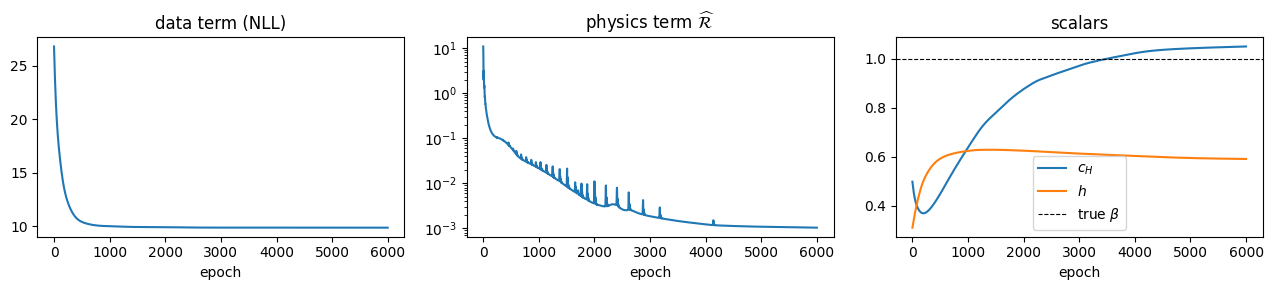

In [15]:
# ═══ [OPTIMISER / GD] ═══  training curves
fig, ax = plt.subplots(1, 3, figsize=(13, 3))
ax[0].plot(hist["nll"]); ax[0].set(title="data term (NLL)", xlabel="epoch")
ax[1].semilogy(hist["R"]); ax[1].set(title="physics term $\\widehat{\\mathcal{R}}$", xlabel="epoch")
ax[2].plot(hist["c_H"], label="$c_H$"); ax[2].plot(hist["h"], label="$h$")
ax[2].axhline(BETA_TRUE, ls="--", c="k", lw=0.8, label="true $\\beta$"); ax[2].legend(); ax[2].set(title="scalars", xlabel="epoch")
plt.tight_layout(); plt.show()

---
# 5 · `[EVAL]` — did we recover the flow?

### 5.1 Learned coefficients
The entropy weight $c_H$ should approach the true temperature $\beta=1$.

In [16]:
# ═══ [EVAL] ═══  coefficients
print(f"c_H = {model.c_H.item():.3f}   (true beta = {BETA_TRUE})")
print(f"h   = {model.h[0].item():.3f}")

c_H = 1.051   (true beta = 1.0)
h   = 0.591


### 5.2 Potential recovery
$V$ is only defined up to a constant, so we compare **centred** potentials on the data support (all training points $y$):
$$R^2 = 1-\frac{\sum_y\big(\tilde V_\theta(y)-\tilde V^\star(y)\big)^2}{\sum_y \tilde V^\star(y)^2},\qquad \tilde V = V - \operatorname{mean}_y V .$$
We use $c_V V_\theta$ consistently (here $c_V=1$; notes §11.5).

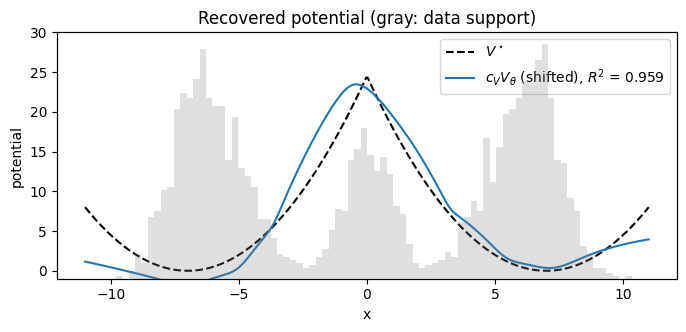

potential R^2 on the data support: 0.959


In [17]:
# ═══ [EVAL] ═══  potential R^2 on the data support
with torch.no_grad():
    Y = torch.cat(list(train.values()))
    Vs, Vt = V_true(Y), model.c_V * model.V(Y)
    Vs, Vt = Vs - Vs.mean(), Vt - Vt.mean()
    R2 = 1 - ((Vt - Vs) ** 2).sum() / (Vs ** 2).sum()

    xs = torch.linspace(-11, 11, 400)[:, None]
    vs, vt = V_true(xs), model.c_V * model.V(xs)
    off = V_true(Y).mean() - (model.c_V * model.V(Y)).mean()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(xs, vs, "k--", label="$V^\\star$")
ax.plot(xs, vt + off, label=f"$c_V V_\\theta$ (shifted), $R^2$ = {R2:.3f}")
ax.set(ylim=(-1, 30), xlabel="x", ylabel="potential", title="Recovered potential (gray: data support)"); ax.legend()
ax2 = ax.twinx(); ax2.hist(Y[:, 0].numpy(), bins=80, density=True, alpha=0.25, color="gray"); ax2.set_yticks([])
plt.show()
print(f"potential R^2 on the data support: {R2:.3f}")

### 5.3 The learned curve
Particle paths $t\mapsto x_{t,k}$ over the training snapshots. The paths are free parameters, not simulated, and the residual made them bend into a gradient flow.

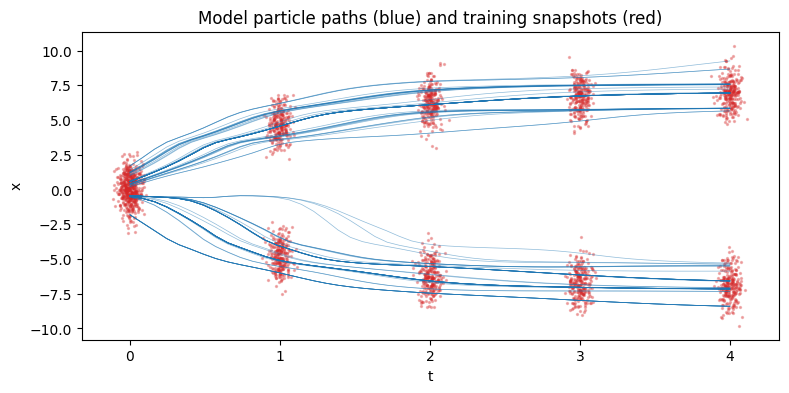

In [18]:
# ═══ [EVAL] ═══  particle trajectories vs data
with torch.no_grad():
    Xp, tg = model.X[:, :, 0].numpy(), model.t_grid.numpy()
fig, ax = plt.subplots(figsize=(9, 4))
for k_ in range(N):
    ax.plot(tg, Xp[:, k_], lw=0.5, c="C0", alpha=0.5)
for s, y in train.items():
    ax.scatter(np.full(len(y), s) + 0.04 * np.random.randn(len(y)), y[:, 0], s=2, c="C3", alpha=0.3)
ax.set(xlabel="t", ylabel="x", title="Model particle paths (blue) and training snapshots (red)")
plt.show()

### 5.4 Held-out times
Compare with the **test** particles at all times, including the held-out times $\{0.5,1.5,2.5,3.5\}$ the model never saw. In 1-D with equal sample sizes, $W_1$ is exact via sorting: $W_1(\mu,\nu)=\frac1M\sum_i|a_{(i)}-b_{(i)}|$.

* **KDE** — sample the learned curve $\rho^\theta_t$ directly: pick particle $k$ with probability $w_k$, then $x_{t,k}+h\odot\varepsilon$. We pick $k$ by *systematic resampling* ($u_m=(m+U)/M$, $k_m=\min\{k:\sum_{l\le k}w_l\ge u_m\}$) rather than i.i.d. draws. With 100 particles and wells 14 apart, i.i.d. draws put a random extra $\sim2\%$ of mass in one well and add $\approx0.3$ to $W_1$ from sampling alone.
* **Learned SDE** — push the test cloud at $t=0$ forward with *our* simulator using the learned energy: $dX = -c_V\nabla V_\theta\,dt + \sqrt{2c_H}\,dB$.
* **True SDE** — the same with $V^\star$, $\beta$ and fresh noise. This is the noise floor from finite samples.

In [19]:
# ═══ [EVAL] ═══  W1 at train and held-out times
def w1_1d(a, b):
    return (a.sort(0).values - b.sort(0).values).abs().mean().item()

def sample_kde(model, s, M, gen):
    with torch.no_grad():
        u = (torch.arange(M) + torch.rand(1, generator=gen)) / M            # systematic resampling
        k_ = torch.searchsorted(torch.cumsum(model.logw.exp(), 0), u).clamp(max=len(model.logw) - 1)
        return model.centres_at(s)[k_] + model.h * torch.randn(M, model.X.shape[-1], generator=gen)

gen_e = torch.Generator().manual_seed(123)
M = len(idx_te)
c_H_hat = model.c_H.item()
learned_gV = lambda x: model.c_V * model.grad_V(x).detach()
sde_learned = simulate(test[0.0], T_ALL, 0.01, c_H_hat, learned_gV, generator=gen_e)
sde_true = simulate(test[0.0], T_ALL, 0.01, BETA_TRUE, grad_V_true, generator=gen_e)

print(f"{'t':>5} {'split':>8} {'KDE':>8} {'learned SDE':>12} {'true SDE':>9}")
for i, t in enumerate(T_ALL):
    print(f"{t:5.1f} {'train' if t in T_TRAIN else 'HELD-OUT':>8} "
          f"{w1_1d(sample_kde(model, t, M, gen_e), test[t]):8.3f} "
          f"{w1_1d(sde_learned[i], test[t]):12.3f} {w1_1d(sde_true[i], test[t]):9.3f}")

    t    split      KDE  learned SDE  true SDE
  0.0    train    0.058        0.000     0.000
  0.5 HELD-OUT    0.531        0.661     0.103
  1.0    train    0.330        1.134     0.135
  1.5 HELD-OUT    0.259        1.372     0.115
  2.0    train    0.278        1.479     0.120
  2.5 HELD-OUT    0.245        1.584     0.176
  3.0    train    0.294        1.604     0.141
  3.5 HELD-OUT    0.247        1.683     0.152
  4.0    train    0.293        1.686     0.192


### 5.5 Why the learned SDE drifts: the barrier is poorly identified
The KDE curve matches the data, but re-simulating the learned SDE from $t=0$ does much worse. In a double-well, the fraction of mass that ends in each well is set by **where the barrier is**: a particle near $x=0$ at $t=0$ goes left or right depending on the sign of $\nabla V$ there. Very few observed or model points ever sit on the barrier (they leave within $\approx0.5$ time units), so the residual barely constrains $V_\theta$ there. A smooth MLP also cannot reproduce the kink of $V^\star$ at $0$.

The potential $R^2$ is averaged over the data support, so it does not see this. A small error in the barrier is invisible in $R^2$ but decides the well fractions of a rollout, and with wells $14$ apart each 1 % of misplaced mass adds $\approx0.14$ to $W_1$.

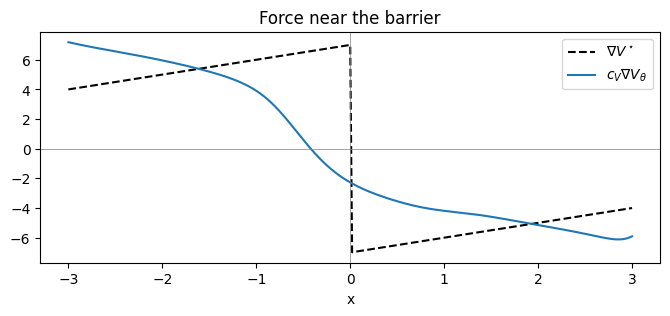

learned barrier (zero of grad V_theta): [-0.44]  true: 0
fraction x > 0 at t = 4:  test data 0.49 | model curve 0.51 | learned SDE 0.62 | true SDE 0.5


In [20]:
# ═══ [EVAL] ═══  barrier diagnosis: force near x = 0 and well fractions
with torch.no_grad():
    xb = torch.linspace(-3, 3, 301)[:, None]
    gs = grad_V_true(xb)[:, 0]
gt = (model.c_V * model.grad_V(xb)).detach()[:, 0]
x_bar = xb[:-1, 0][(gt[:-1] > 0) & (gt[1:] <= 0)]

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(xb, gs, "k--", label="$\\nabla V^\\star$"); ax.plot(xb, gt, label="$c_V\\nabla V_\\theta$")
ax.axhline(0, c="gray", lw=0.5); ax.axvline(0, c="gray", lw=0.5)
ax.set(xlabel="x", title="Force near the barrier"); ax.legend(); plt.show()

frac = lambda Z: round((Z > 0).double().mean().item(), 2)
print("learned barrier (zero of grad V_theta):", [round(v, 2) for v in x_bar.tolist()], " true: 0")
print("fraction x > 0 at t = 4:  test data", frac(test[4.0]), "| model curve", frac(model.centres_at(4.0)),
      "| learned SDE", frac(sde_learned[-1]), "| true SDE", frac(sde_true[-1]))

---
# 6 · Roadmap: the other tasks

From `00_reference_repo_structure.md` §10 and the notes' reproduction checklist (§11).

| # | Notebook / task | Status |
|---|---|---|
| — | forward simulator `wgf/sim.py` (Euler–Maruyama, Heun) + tests | ✅ done |
| 00 | **this notebook**: full pipeline on the 1-D double-well | ✅ done |
| 01 | KDE, score (full vs LOO), Nadaraya–Watson velocity (Eq. 9); NW → $\dot x_k$ as $h\to0$; continuity residual of the KDE ≈ 0 | ⬜ |
| 02 | energies: $V_\theta$, radial $W_\theta$, entropy; check $\frac{d}{dt}\mathcal F = -\lVert g\rVert^2_\rho$ on the exact OU flow | ⬜ |
| 03 | residual estimators: Euler / trapezoid / midpoint / implicit; KDE-Monte-Carlo estimator ($\alpha>0$, App. C) | ⬜ |
| 04 | double-well regimes: dense / terminal / trickle observations; **fix the barrier** found in §5.5 (more particles / snapshots near $t=0$, full vs LOO score, seeds) | ⬜ |
| 05 | wavy valley vs our JKOnet* baseline (Fig. 1, chord bias) | ⬜ |
| 06 | 15 synthetic 2-D potentials, paired vs unpaired; potential $R^2$, $L^2$-UVP, Bd²W₂-UVP (Tab. 1/4) | ⬜ |
| 07 | EB single-cell RNA (5 PCs): static vs time-conditioned $V_\theta(x,t)$, leave-two-out (Tab. 2/5) | ⬜ |
| 08 | interaction ($V$ + $W$, McKean–Vlasov, Tab. 3) and chiral non-gradient flow | ⬜ |
| — | move notebook code into `wgf/{kde,energy,residual,model,train,metrics}.py` | ⬜ |

**Deliberate choices so far** (keep a log of them):
* noise $\sigma=\sqrt{2\beta}$ (not $\sqrt2\,c_H$);
* LOO score by default, full score as an ablation (`SCORE`);
* per-snapshot NLL (equal weight per snapshot);
* $c_V$ fixed at 1 to remove the $c_V V_\theta$ scale redundancy;
* wavy-valley tilt $\tau = 0.3$ (paper App. E), not $0.5$.